In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Mathematics in Motor Insurance

## Understanding Risk Through Probability, Statistics and Mathematical Models

### Project Overview

Insurance companies need to estimate the risk of future claims in order to calculate appropriate insurance premiums. Mathematics plays an important role in this process because insurance claims are uncertain events, and their frequency and financial impact can vary significantly.

The main goal of this project is to explore how mathematical concepts can be applied to real motor insurance data to understand insurance risk, estimate expected financial losses, and calculate illustrative insurance premiums.

The project focuses on the following mathematical areas:

- **Descriptive Statistics:** Analyzing the distribution of insurance claims and financial losses using mean, median, variance, standard deviation, and other statistical measures.
- **Probability Theory:** Calculating the probability of insurance claims, exploring conditional probabilities, and examining probability distributions.
- **Mathematical Functions:** Investigating how insurance risk changes with driver age and vehicle age using mathematical relationships and functions.
- **Correlation Analysis:** Measuring relationships between driver characteristics, vehicle characteristics, claim frequency, and financial losses.
- **Expected Value and Mathematical Modeling:** Using mathematical expectations to estimate future insurance losses and develop a simplified insurance premium calculation model.

### Research Objectives

The project aims to answer the following questions:

1. What is the probability of an insurance claim, and how does it vary across different groups of drivers and vehicles?
2. How are insurance claims and financial losses distributed?
3. What statistical relationships exist between driver age, vehicle age, and insurance risk?
4. How can mathematical functions and probability models describe insurance claim frequency and expected losses?
5. How can these mathematical results be used to calculate illustrative insurance premiums?

### Methodology

Each mathematical area follows the same approach:

**Mathematical Theory → Formulas → Python Implementation → Visualization → Interpretation of Results**

This structure helps explain the mathematical concepts, apply them to real insurance data, and understand the results.

Python and Jupyter Notebook are used for mathematical calculations, statistical analysis, and data visualization.

The objective is not only to analyze insurance data but also to demonstrate how mathematics can be applied to a real-world problem.

## 1. How Do Vehicle Characteristics Affect Insurance Premiums?

Insurance premiums can depend on several vehicle characteristics, such as engine power, vehicle value, and weight.

In this section, we will investigate whether these characteristics can be used to estimate insurance premiums using a simple mathematical model.

We will compare the estimated premiums with the actual premiums in our dataset.

### 1.1 Mathematical Model

We will use multiple linear regression to estimate insurance premiums based on three vehicle characteristics.

The formula is:

$$
\hat{P} = b_0 + b_1x_1 + b_2x_2 + b_3x_3
$$

where:

- $\hat{P}$ — estimated insurance premium.
- $x_1$ — engine power (`Power`).
- $x_2$ — vehicle value (`Value_vehicle`).
- $x_3$ — vehicle weight (`Weight`).
- $b_0$ — intercept.
- $b_1, b_2, b_3$ — coefficients calculated from our dataset.

We will use linear algebra to calculate the coefficients and compare the estimated premiums with the actual values.

**References:**

- SoftUni, *Linear Algebra – Material Summary
- *Simple and Multiple Linear Regression*

In [129]:
# Select the vehicle characteristics and actual insurance premiums
insurance_data = df[['Power', 'Value_vehicle', 'Weight', 'Premium']].copy()

# Remove rows with missing values
insurance_data = insurance_data.dropna()

# Display the first five records
insurance_data.head()

,Power,Value_vehicle,Weight,Premium
0,80,7068.0,190,222.52
1,80,7068.0,190,213.78
2,80,7068.0,190,214.84
3,80,7068.0,190,216.99
4,80,7068.0,190,213.70


In [130]:
# Create a matrix with the vehicle characteristics
X = insurance_data[['Power', 'Value_vehicle', 'Weight']].to_numpy()

# Create a vector with the actual premiums
y = insurance_data['Premium'].to_numpy()

# Add a column of ones for the intercept
X = np.column_stack((np.ones(len(X)), X))

# Calculate the coefficients using least squares
coefficients = np.linalg.lstsq(X, y, rcond=None)[0]

# Display the calculated coefficients
print(f"b0 = {coefficients[0]:.4f}")
print(f"b1 = {coefficients[1]:.4f}")
print(f"b2 = {coefficients[2]:.4f}")
print(f"b3 = {coefficients[3]:.4f}")

b0 = 167.2974
b1 = 1.0595
b2 = 0.0035
b3 = -0.0121


In [131]:
# Calculate estimated premiums using matrix multiplication
insurance_data['Predicted_Premium'] = X @ coefficients

# Compare actual and estimated premiums
insurance_data[['Premium', 'Predicted_Premium']].head(10).round(2)

,Premium,Predicted_Premium
0,222.52,274.64
1,213.78,274.64
2,214.84,274.64
3,216.99,274.64
4,213.70,274.64
5,215.83,274.64
6,380.20,300.40
7,393.50,300.40
8,393.50,300.40
9,395.47,300.40


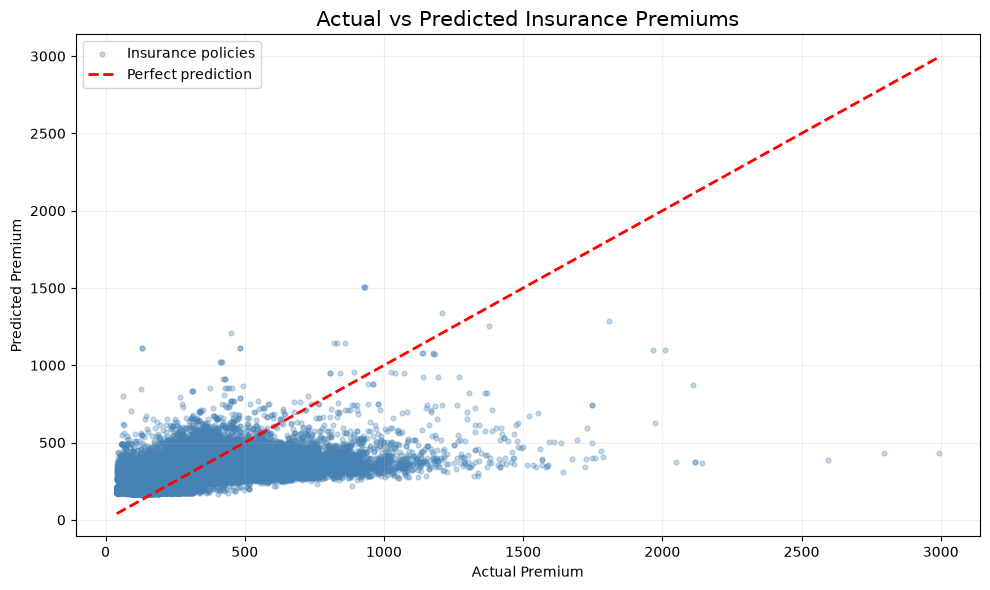

In [132]:
# Compare actual and predicted insurance premiums
plt.figure(figsize=(10, 6))

plt.scatter(
    insurance_data['Premium'],
    insurance_data['Predicted_Premium'],
    alpha=0.3,
    s=12,
    color='steelblue',
    label='Insurance policies'
)

# Draw the line representing perfect predictions
min_val = min(insurance_data['Premium'].min(), insurance_data['Predicted_Premium'].min())
max_val = max(insurance_data['Premium'].max(), insurance_data['Predicted_Premium'].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2,
    label='Perfect prediction'
)

plt.title('Actual vs Predicted Insurance Premiums', fontsize=15)
plt.xlabel('Actual Premium')
plt.ylabel('Predicted Premium')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 1.2 Interpretation of Results

The graph compares actual insurance premiums with the premiums calculated by our model.

Blue dots represent individual insurance records.

Red dashed line represents perfect predictions, where the estimated premium equals the actual premium.

Dots above the line indicate overestimated premiums.

Dots below the line indicate underestimated premiums.

Observations:

The model tends to overestimate lower premiums and underestimate higher premiums. Most predicted values are concentrated in a narrow range, while actual premiums vary significantly.

Conclusion:

Engine power, vehicle value, and weight are not enough to accurately predict all insurance premiums. Other factors may also influence the premium.

This analysis shows both the practical application of linear algebra and the limitations of our simple regression model.

### 1.3 Measuring Prediction Errors

To measure how accurate our model is, we will calculate the Mean Absolute Error (MAE).

The formula is:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|P_i-\hat{P}_i|
$$

where:

- $P_i$ — actual insurance premium.
- $\hat{P}_i$ — predicted insurance premium.
- $n$ — total number of insurance records.

MAE shows the average difference between actual and predicted premiums. A lower MAE means more accurate predictions.

**Source:** [scikit-learn — Mean Absolute Error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html)


In [133]:
# Calculate the absolute difference for each insurance record
absolute_errors = np.abs(
    insurance_data['Premium'] - insurance_data['Predicted_Premium']
)

# Calculate the average prediction error
mae = np.mean(absolute_errors)

print(f"Mean Absolute Error (MAE): {mae:.2f}")

Mean Absolute Error (MAE): 84.28


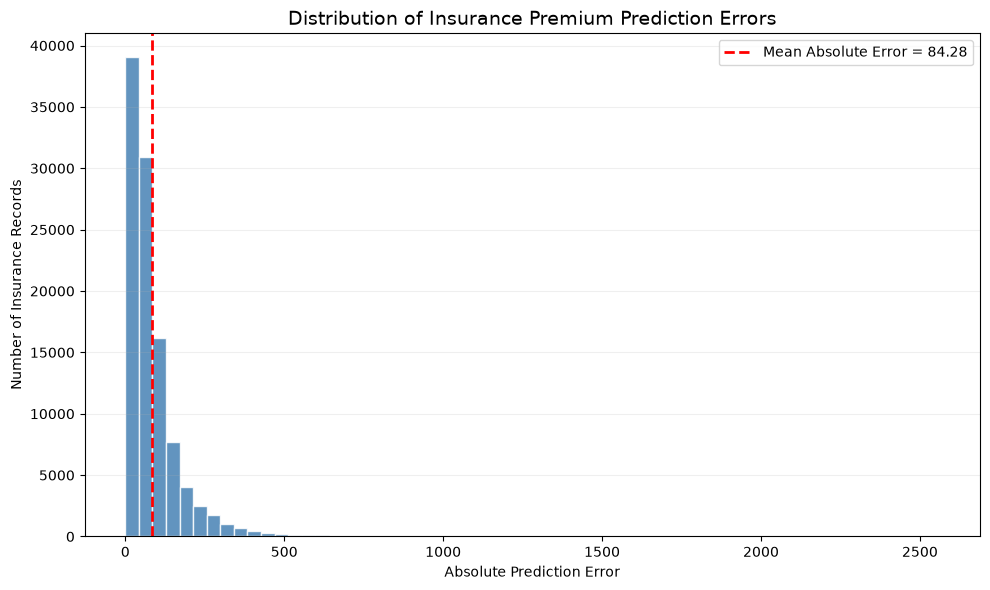

In [134]:
# Calculate absolute prediction errors
absolute_errors = np.abs(
    insurance_data['Premium'] - insurance_data['Predicted_Premium']
)

# Create a histogram of prediction errors
plt.figure(figsize=(10, 6))

plt.hist(
    absolute_errors,
    bins=60,
    color='steelblue',
    edgecolor='white',
    alpha=0.85
)

# Show the average absolute error
plt.axvline(
    mae,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean Absolute Error = {mae:.2f}'
)

plt.title('Distribution of Insurance Premium Prediction Errors', fontsize=14)
plt.xlabel('Absolute Prediction Error')
plt.ylabel('Number of Insurance Records')

plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

### 1.5 Distribution of Prediction Errors

The histogram shows the distribution of absolute prediction errors in our insurance dataset.

- **X-axis (Absolute Prediction Error)** — the difference between the actual and predicted premium, without considering whether the prediction is higher or lower.
- **Y-axis (Number of Insurance Records)** — the number of insurance records in each error range.
- **Blue bars** — show how frequently different prediction errors occur.
- **Red dashed line** — represents the Mean Absolute Error (MAE) of **84.28**.

The histogram helps us understand how prediction errors are distributed across insurance records.

The MAE of 84.28 means that the predicted premiums differ from the actual premiums by an average of 84.28 monetary units.

**Conclusion:**

The histogram provides additional information about the model's accuracy by showing the frequency of different prediction errors, while MAE summarizes these errors in a single value.

## 2. Calculus — How Does Engine Power Affect Insurance Premiums?

In the previous section, we created a linear regression model to estimate insurance premiums using three vehicle characteristics.

Now we will use calculus to investigate how changes in engine power affect the estimated premium.

### 2.1 Partial Derivatives

A partial derivative measures how a function changes when one variable changes while the other variables remain constant.

Our regression model is:

$$
\hat{P} = b_0 + b_1x_1 + b_2x_2 + b_3x_3
$$

To investigate the effect of engine power, we calculate the partial derivative with respect to $x_1$:

$$
\frac{\partial \hat{P}}{\partial x_1} = b_1
$$

From our previous calculations:

$$
\frac{\partial \hat{P}}{\partial x_1} = 1.0595
$$

This means that increasing engine power by one unit increases the estimated insurance premium by approximately **1.06 monetary units**, assuming vehicle value and weight remain constant.

This result describes the behaviour of our mathematical model, not necessarily a causal relationship in real insurance pricing.

**Reference:**
- SoftUni, *Calculus – Material Summary*

### 2.2 - Calculating Premiums for Different Engine Powers
We use our regression model to calculate estimated insurance premiums for engine power values between 50 and 250.

During the calculation:
- Engine power changes from 50 to 250 in steps of 10.
- Vehicle value remains constant at its median value.
- Vehicle weight remains constant at its median value.

According to our partial derivative:

$$
\frac{\partial \hat{P}}{\partial x_1} = 1.0595
$$

For every increase of 10 units in engine power, the estimated premium increases by approximately:

In [135]:
# Generate engine power values from 50 to 250
power_values = np.arange(50, 251, 10)

# Keep vehicle value and weight constant
vehicle_value = insurance_data['Value_vehicle'].median()
vehicle_weight = insurance_data['Weight'].median()

# Calculate predicted premiums for different engine powers
predicted_premiums = (
    coefficients[0]
    + coefficients[1] * power_values
    + coefficients[2] * vehicle_value
    + coefficients[3] * vehicle_weight
)

# Display the first five results
for power, premium in zip(power_values[:5], predicted_premiums[:5]):
    print(f"Power: {power} | Predicted Premium: {premium:.2f}")

Power: 50 | Predicted Premium: 267.67
Power: 60 | Predicted Premium: 278.26
Power: 70 | Predicted Premium: 288.86
Power: 80 | Predicted Premium: 299.45
Power: 90 | Predicted Premium: 310.05


The calculated results confirm our partial derivative.

For every 10 additional units of engine power, the predicted insurance premium increases by approximately 10.60 monetary units.

This demonstrates how derivatives can help us understand changes in insurance premiums.

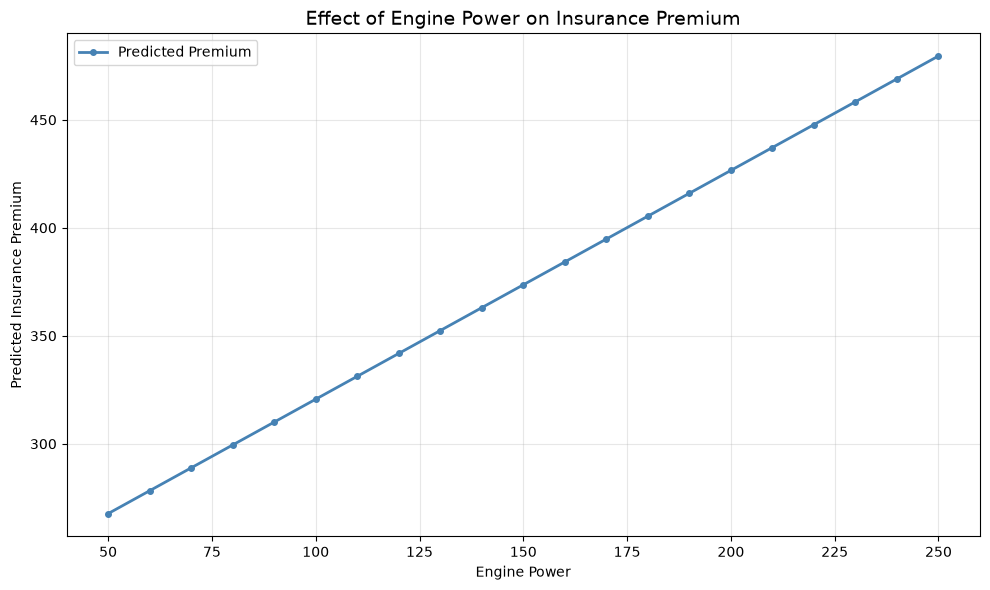

In [136]:
# Plot predicted premiums for different engine power values
plt.figure(figsize=(10, 6))

plt.plot(
    power_values,
    predicted_premiums,
    color='steelblue',
    linewidth=2,
    marker='o',
    markersize=4,
    label='Predicted Premium'
)

plt.title('Effect of Engine Power on Insurance Premium', fontsize=14)
plt.xlabel('Engine Power')
plt.ylabel('Predicted Insurance Premium')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2.3 Interpretation of the Graph

The graph shows how the predicted insurance premium changes as engine power increases, while vehicle value and weight remain constant.

We observe a straight, upward-sloping line.

This happens because our regression model is linear, and the partial derivative with respect to engine power is constant:

$$
\frac{\partial \hat{P}}{\partial x_1} = 1.0595
$$

For every 10 additional units of engine power, the predicted premium increases by approximately 10.60 monetary units.

Conclusion:

The graph demonstrates how partial derivatives can be used to measure changes in predicted insurance premiums.

The relationship is linear because of the mathematical model we selected. Actual insurance premiums may depend on additional factors and may not follow the same pattern.

### 2.4 Definite Integrals — Insurance Premium Analysis

In the previous section, we investigated how engine power affects predicted insurance premiums using partial derivatives.

Now we will use definite integrals to calculate the area under the predicted premium curve.

According to the Calculus lecture, a definite integral can be calculated as the limit of a sum of small areas:

$$
\int_a^b f(x)\,dx =
\lim_{\Delta x \to 0}\sum_{i=1}^{n}f(x_i)\Delta x
$$

where:
- $f(x)$ — the function we are investigating.
- $a$ and $b$ — the lower and upper limits.
- $\Delta x$ — the width of each small interval.
- $n$ — the number of intervals.

We will apply this concept to our regression model:

Our predicted insurance premium function is:

$$
\hat{P}(x) = C + 1.0595x
$$

where:
- $\hat{P}(x)$ — predicted insurance premium.
- $x$ — engine power.
- $1.0595$ — the coefficient calculated in our regression model.
- $C$ — the constant part of the model, which includes the intercept and the effects of vehicle value and weight.

We keep vehicle value and weight constant and investigate only changes in engine power.

We want to calculate the area under the predicted premium curve between engine power values of 50 and 250:

$$
A = \int_{50}^{250}\hat{P}(x)\,dx
$$

where:
- $A$ — the area under the predicted premium curve.
- $50$ — the lower limit of engine power.
- $250$ — the upper limit of engine power.
- $\hat{P}(x)$ — our predicted premium function.

To approximate this integral in Python, we divide the interval into small rectangles and add their areas:

$$
A \approx \sum_{i=1}^{n}\hat{P}(x_i)\Delta x
$$

where:
- $n$ — the number of rectangles.
- $x_i$ — the engine power value used for each rectangle.
- $\hat{P}(x_i)$ — the height of each rectangle (predicted premium).
- $\Delta x$ — the width of each rectangle.

Each rectangle has an area of:

$$
S_i = \hat{P}(x_i)\Delta x
$$

By adding the areas of all rectangles, we approximate the definite integral.

As the rectangles become narrower, the approximation becomes more accurate.

**Reference:**
- SoftUni, *Calculus – Material Summary

добре, дай ми маркдаун клетката
### 2.5 Interpretation of the Integral Visualization

The graph shows how we can estimate the area under the predicted insurance premium curve using integrals.

- **Blue line** — represents the predicted insurance premium.
- **Light blue area** — shows the area under the curve between engine power values of 50 and 250.
- **Orange rectangles** — are used to calculate the area using intervals of width 10.

We calculate the total area by adding the areas of all rectangles.

Because the function is increasing, the rectangles give us a slightly smaller result than the actual area.

**Conclusion:**

From this analysis, we can see how integrals can be used with our insurance premium model. We also observe that using smaller intervals gives us a more accurate result.

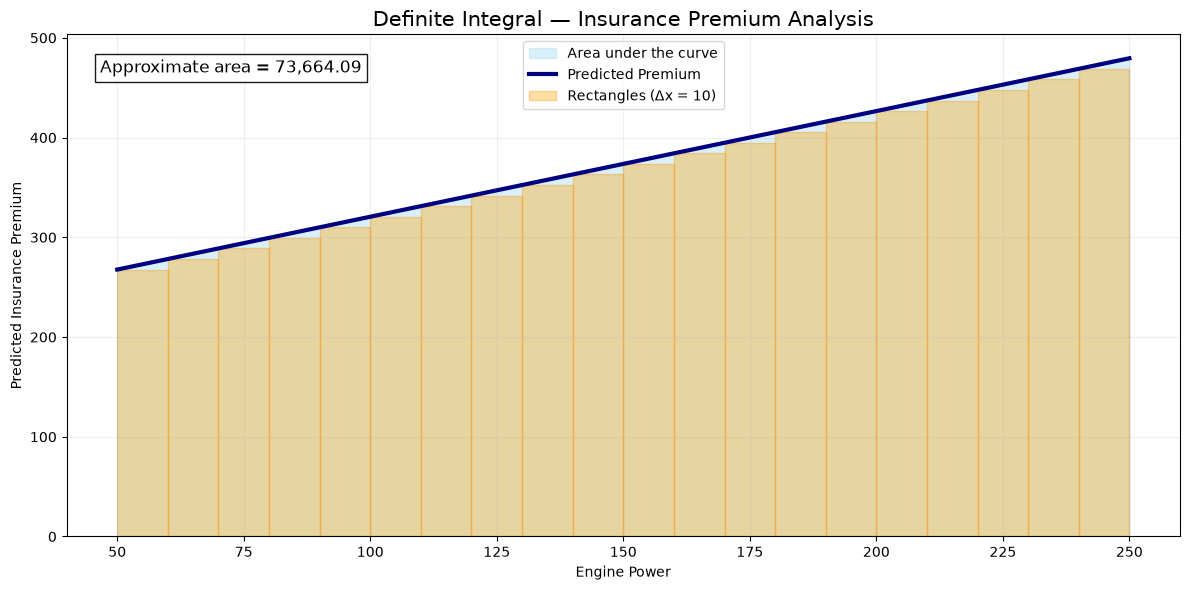

In [137]:

# Define the engine power interval
a, b = 50, 250

# Keep vehicle value and weight constant
vehicle_value = insurance_data['Value_vehicle'].median()
vehicle_weight = insurance_data['Weight'].median()

# Define the constant part of our regression model
C = (
    coefficients[0]
    + coefficients[2] * vehicle_value
    + coefficients[3] * vehicle_weight
)

# Define the predicted premium function
def premium_function(power):
    return C + coefficients[1] * power

# Create points for the smooth line
x = np.linspace(a, b, 500)
y = premium_function(x)

# Create rectangles with a width of 10
dx = 10
rectangle_x = np.arange(a, b, dx)
rectangle_y = premium_function(rectangle_x)

# Approximate the integral using rectangles
area = np.sum(rectangle_y * dx)

# Create the graph
plt.figure(figsize=(12, 6))

# Shade the area under the curve
plt.fill_between(
    x, y,
    color='skyblue',
    alpha=0.3,
    label='Area under the curve'
)

# Draw the rectangles
plt.bar(
    rectangle_x,
    rectangle_y,
    width=dx,
    align='edge',
    color='orange',
    alpha=0.35,
    edgecolor='darkorange',
    label='Rectangles (Δx = 10)'
)

# Draw the predicted premium function
plt.plot(
    x, y,
    color='navy',
    linewidth=3,
    label='Predicted Premium'
)

plt.title('Definite Integral — Insurance Premium Analysis', fontsize=15)
plt.xlabel('Engine Power')
plt.ylabel('Predicted Insurance Premium')

plt.text(
    0.03, 0.95,
    f'Approximate area = {area:,.2f}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.9)
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 3. How Likely Is an Insurance Claim?

### 3.1 Calculating the Probability of an Insurance Claim

In this section, we will calculate how often insurance claims occur in our dataset.

We want to find the probability that a randomly selected insurance record has a registered claim.

According to the Probability and Combinatorics lecture, the frequency of an event is calculated using the formula:

$$
f = \frac{m}{n}
$$

where:
- $f$ — the frequency of the event.
- $m$ — the number of records with a registered insurance claim.
- $n$ — the total number of insurance records.

We will use this formula to calculate the claim frequency in our dataset and express the result as a percentage.

This frequency will help us estimate the probability of an insurance claim based on the available data.

**Reference:**
- SoftUni, *Probability and Combinatorics

In [138]:
# Display all column names in the dataset
print(df.columns.tolist())

['ID', 'Date_start_contract', 'Date_last_renewal', 'Date_next_renewal', 'Date_birth', 'Date_driving_licence', 'Distribution_channel', 'Seniority', 'Policies_in_force', 'Max_policies', 'Max_products', 'Lapse', 'Date_lapse', 'Payment', 'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history', 'R_Claims_history', 'Type_risk', 'Area', 'Second_driver', 'Year_matriculation', 'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Type_fuel', 'Length', 'Weight']


### Calculating Claim Frequency with Python

We will use the `N_claims_year` column to calculate claim frequency.

We will count the records with at least one claim and divide them by the total number of valid records.

The result will show the estimated probability of an insurance claim as a percentage.

In [139]:
# Select records with available claim information
claims_data = df['N_claims_year'].dropna()

# Count records with at least one insurance claim
claims_count = (claims_data > 0).sum()

# Count all records with available claim information
total_records = len(claims_data)

# Calculate claim frequency
claim_frequency = claims_count / total_records

print(f"Total records: {total_records}")
print(f"Records with claims: {claims_count}")
print(f"Claim frequency: {claim_frequency:.4f}")
print(f"Claim probability estimate: {claim_frequency:.2%}")

Total records: 105555
Records with claims: 19646
Claim frequency: 0.1861
Claim probability estimate: 18.61%


### Interpretation of Results

The graph shows the percentage of insurance records with 0, 1, 2, and 3 or more claims.

Our calculations show that **81.39% of insurance records have no claims**, while **18.61% have at least one claim**.

By dividing the records into groups, we can also see how common multiple claims are.

**Conclusion:**

The probability of selecting a record with at least one claim is estimated at **18.61%** based on our dataset. The graph helps us understand how insurance claims are distributed and how often multiple claims occur.

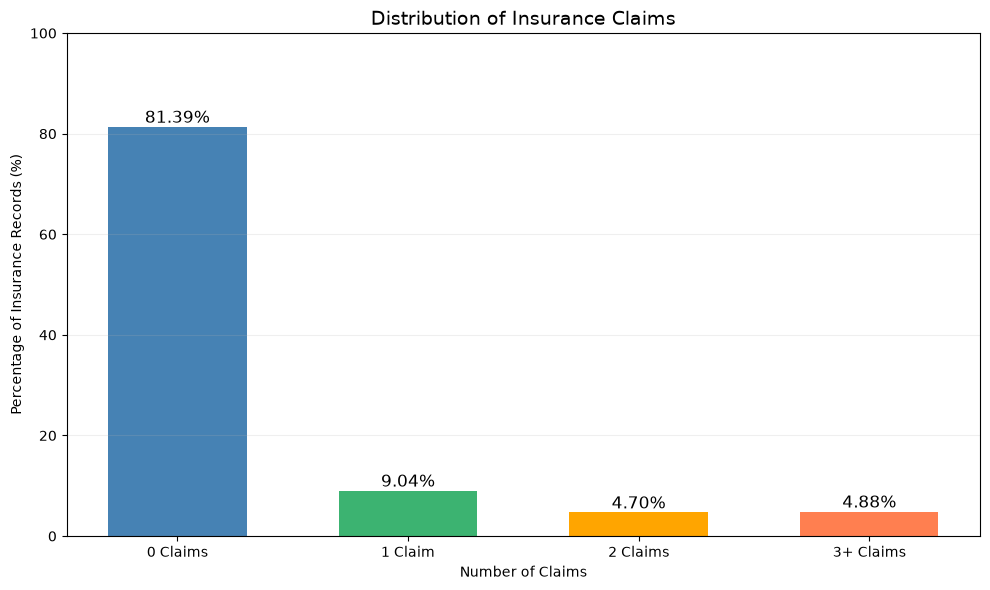

In [140]:
# Group insurance records by number of claims
claim_groups = pd.cut(
    claims_data,
    bins=[-1, 0, 1, 2, float('inf')],
    labels=['0 Claims', '1 Claim', '2 Claims', '3+ Claims']
)

# Calculate the percentage of records in each group
claim_percentages = (
    claim_groups.value_counts(sort=False) / total_records * 100
)

# Create the bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    claim_percentages.index,
    claim_percentages.values,
    color=['steelblue', 'mediumseagreen', 'orange', 'coral'],
    width=0.6
)

# Display percentages above the bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f'{bar.get_height():.2f}%',
        ha='center',
        fontsize=12
    )

plt.title('Distribution of Insurance Claims', fontsize=14)
plt.xlabel('Number of Claims')
plt.ylabel('Percentage of Insurance Records (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

3.2 How Does Driver Age Affect Claim Probability?

In the previous section, we calculated that 18.61% of insurance records have at least one registered claim.

Now we want to investigate whether claim probability changes depending on the driver's age.

We will use conditional probability to calculate the probability of a claim for drivers aged 18–24.

According to the Probability and Combinatorics lecture, conditional probability is calculated using the formula:

$$
P(A \mid B) = \frac{P(A \cap B)}{P(B)}
$$

where:

$A$ — an insurance record has at least one registered claim.

$B$ — the driver is aged 18–24.

$P(A \cap B)$ — the probability that both events occur.

$P(B)$ — the probability that a driver belongs to this age group.

$P(A \mid B)$ — the probability of a claim within this age group.

Applying the formula to our dataset:

$$
P(\text{Claim} \mid \text{Age 18–24}) =
\frac{\text{Number of records with claims for drivers aged 18–24}}
{\text{Total number of records for drivers aged 18–24}}
$$

We will calculate the drivers' ages at the start of their insurance contracts using Date_birth and Date_start_contract.

Then, we will use Python to calculate the conditional probability and compare it with the overall claim probability of 18.61%.

Reference:

SoftUni, Probability and Combinatorics 

### Calculating Conditional Claim Probability

We will use conditional probability to calculate the chance of an insurance claim for drivers aged 18–24.

We will divide the number of insurance records with claims in this age group by the total number of records in the same group.

In [141]:
# Select valid records
age_data = df[['Date_birth', 'Date_start_contract', 'N_claims_year']].copy()

# Convert dates
age_data['Date_birth'] = pd.to_datetime(
    age_data['Date_birth'], errors='coerce', dayfirst=True
)

age_data['Date_start_contract'] = pd.to_datetime(
    age_data['Date_start_contract'], errors='coerce', dayfirst=True
)

# Calculate age at the start of the contract
age_data['Driver_age'] = (
    age_data['Date_start_contract'].dt.year
    - age_data['Date_birth'].dt.year
    - (
        (age_data['Date_start_contract'].dt.strftime('%m%d')
         < age_data['Date_birth'].dt.strftime('%m%d'))
    )
)

# Remove missing and unrealistic values
age_data = age_data.dropna(subset=['Driver_age', 'N_claims_year'])
age_data = age_data[age_data['Driver_age'].between(18, 100)]

# Event B: driver is aged 18–24
group_18_24 = age_data['Driver_age'].between(18, 24)

# Event A: record has at least one claim
has_claim = age_data['N_claims_year'] > 0

# Calculate P(B) and P(A ∩ B)
p_b = group_18_24.mean()
p_a_and_b = (group_18_24 & has_claim).mean()

# Calculate P(A | B)
if p_b > 0:
    conditional_probability = p_a_and_b / p_b

    print(f"P(B): {p_b:.4f}")
    print(f"P(A ∩ B): {p_a_and_b:.4f}")
    print(f"P(A | B): {conditional_probability:.2%}")
else:
    print("No records found for drivers aged 18–24.")

P(B): 0.0519
P(A ∩ B): 0.0092
P(A | B): 17.67%


### Preparing Driver Age Data with Python

Before calculating claim probabilities, we need to determine the drivers' ages.

We will use the `Date_birth` column to calculate each driver's age at the start of their insurance contract.

First, we will check the date format to make sure the data can be processed correctly.

In [142]:
# Check the format of birth dates
print(df['Date_birth'].head(10))
print(df['Date_birth'].dtype)

0    15/04/1956
1    15/04/1956
2    15/04/1956
3    15/04/1956
4    15/04/1956
5    15/04/1956
6    18/03/1975
7    18/03/1975
8    18/03/1975
9    18/03/1975
Name: Date_birth, dtype: str
str


###  Visualizing Claim Probability by Driver Age

We will compare claim probabilities across different age groups and use the overall claim probability of 18.61% as a reference.

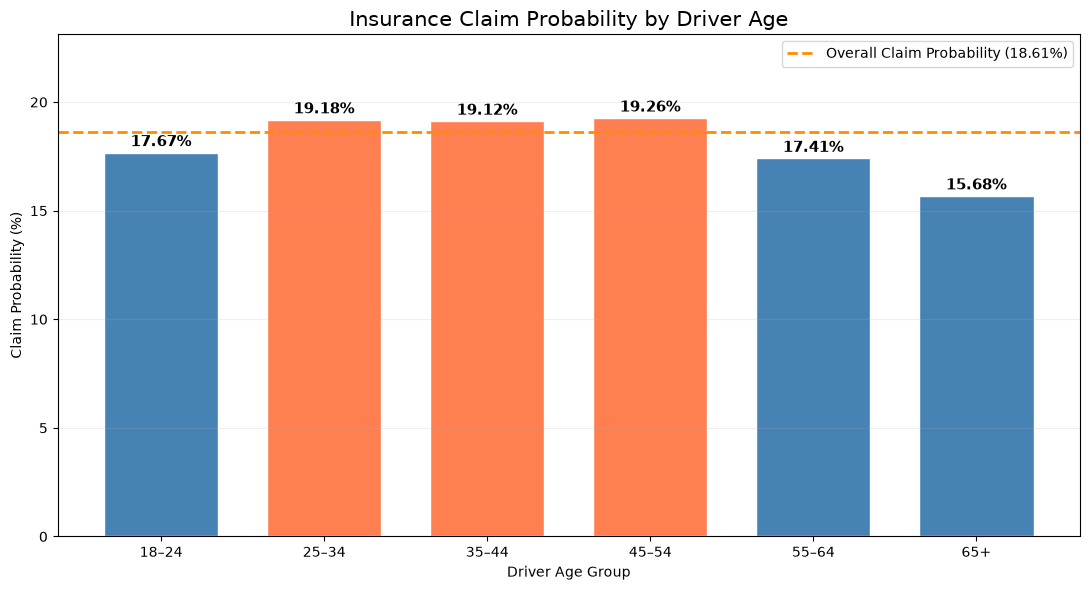

In [143]:
# Prepare the data
age_data = df[['Date_birth', 'Date_start_contract', 'N_claims_year']].copy()

# Convert dates
age_data['Date_birth'] = pd.to_datetime(age_data['Date_birth'], errors='coerce', dayfirst=True)
age_data['Date_start_contract'] = pd.to_datetime(
    age_data['Date_start_contract'], errors='coerce', dayfirst=True
)

# Calculate driver age at the start of the contract
age_data['Driver_age'] = (
    age_data['Date_start_contract'].dt.year -
    age_data['Date_birth'].dt.year -
    (
        (age_data['Date_start_contract'].dt.month * 100 +
         age_data['Date_start_contract'].dt.day)
        <
        (age_data['Date_birth'].dt.month * 100 +
         age_data['Date_birth'].dt.day)
    )
)

# Remove missing or unrealistic values
age_data = age_data.dropna(subset=['Driver_age', 'N_claims_year'])
age_data = age_data[age_data['Driver_age'].between(18, 100)]

# Create age groups
age_data['Age_group'] = pd.cut(
    age_data['Driver_age'],
    bins=[18, 25, 35, 45, 55, 65, 101],
    right=False,
    labels=['18–24', '25–34', '35–44', '45–54', '55–64', '65+']
)

# Calculate conditional claim probability for each age group
claim_probability_by_age = (
    age_data.groupby('Age_group', observed=True)['N_claims_year']
    .apply(lambda claims: (claims > 0).mean() * 100)
)

# Create the chart
plt.figure(figsize=(11, 6))

colors = [
    'coral' if probability > claim_frequency * 100 else 'steelblue'
    for probability in claim_probability_by_age
]

bars = plt.bar(
    claim_probability_by_age.index,
    claim_probability_by_age.values,
    color=colors,
    edgecolor='white',
    width=0.7
)

# Add percentages above the bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f'{bar.get_height():.2f}%',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

# Add the overall claim probability
plt.axhline(
    claim_frequency * 100,
    color='darkorange',
    linestyle='--',
    linewidth=2,
    label=f'Overall Claim Probability ({claim_frequency:.2%})'
)

plt.title('Insurance Claim Probability by Driver Age', fontsize=15)
plt.xlabel('Driver Age Group')
plt.ylabel('Claim Probability (%)')
plt.ylim(0, max(claim_probability_by_age.max(), claim_frequency * 100) * 1.2)
plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Statistics — What Can We Learn from Insurance Claim Costs?

### 4.1 How Much Do Insurance Claims Cost?

In this section, we will use **descriptive statistics** to analyze insurance claim costs from the `Cost_claims_year` column.

We will focus on insurance records with positive claim costs and calculate three statistical measures: **mean, median, and standard deviation**.

These calculations will help us understand the typical cost of insurance claims and how much the costs vary.

#### 1. Mean (Average)

The mean represents the average claim cost and is calculated using the formula:

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n}x_i
$$

where:
- $x_i$ — the claim cost for each insurance record.
- $n$ — the number of records with positive claim costs.
- $\bar{x}$ — the average claim cost.

**How we will use it:**

We will add together all positive claim costs and divide the total by the number of records included in the calculation.

This will show us the **average cost per insurance record with a positive claim cost**.

#### 2. Median

The median is the middle value when all claim costs are arranged in ascending order.

For an odd number of observations:

$$
\text{Median} = x_{\frac{n+1}{2}}
$$

For an even number of observations:

$$
\text{Median} = \frac{x_{\frac{n}{2}} + x_{\frac{n}{2}+1}}{2}
$$

Here, $x_i$ represents the value at position $i$ in the sorted data.

**How we will use it:**

We will sort the claim costs and find the middle value.

By comparing the median with the mean, we can investigate whether unusually expensive claims increase the average.

#### 3. Standard Deviation

Standard deviation measures how much claim costs vary around their mean.

We will calculate the sample standard deviation using:

$$
s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}
$$

where:
- $s$ — the standard deviation.
- $x_i$ — the claim cost for each record.
- $\bar{x}$ — the mean claim cost.
- $n$ — the number of observations.

**How we will use it:**

We will calculate the difference between each claim cost and the mean, square these differences, add them together, divide by $n-1$, and take the square root.

A higher standard deviation indicates that claim costs vary more widely.

### Applying the Formulas with Python

We will use Python to:

1. Select insurance records with positive claim costs.
2. Calculate the mean using the mathematical formula.
3. Calculate the median from the sorted claim costs.
4. Calculate the standard deviation using the previously calculated mean.
5. Visualize the distribution of claim costs using a box plot.

Finally, we will compare the results to understand whether insurance claim costs are relatively consistent or whether some claims are significantly more expensive than others.

**Reference:**
- SoftUni, *Statistics

###  Calculating Claim Cost Statistics with Python

We will apply the mathematical formulas to calculate the mean, median, and standard deviation of positive insurance claim costs.

In [144]:
# Select records with positive claim costs
claim_costs = df.loc[df['Cost_claims_year'] > 0, 'Cost_claims_year'].dropna()

# Number of observations
n = len(claim_costs)

# 1. Mean: sum of claim costs divided by the number of observations
mean_cost = claim_costs.sum() / n

# 2. Median: find the middle value in the sorted data
sorted_costs = np.sort(claim_costs.to_numpy())

if n % 2 == 1:
    median_cost = sorted_costs[n // 2]
else:
    median_cost = (
        sorted_costs[n // 2 - 1] + sorted_costs[n // 2]
    ) / 2

# 3. Standard deviation: calculate deviations from the mean
squared_differences = (claim_costs - mean_cost) ** 2

std_cost = np.sqrt(squared_differences.sum() / (n - 1))

# Display results
print(f"Records with positive claim costs: {n:,}")
print(f"Mean claim cost: {mean_cost:,.2f}")
print(f"Median claim cost: {median_cost:,.2f}")
print(f"Standard deviation: {std_cost:,.2f}")

Records with positive claim costs: 19,646
Mean claim cost: 825.04
Median claim cost: 289.44
Standard deviation: 3,342.05


### Visualizing Insurance Claim Costs

We will use a histogram to visualize the distribution of insurance claim costs.

The graph will show how many insurance records fall into different cost ranges.

We will also add the mean and median to compare the average claim cost with the typical claim cost.

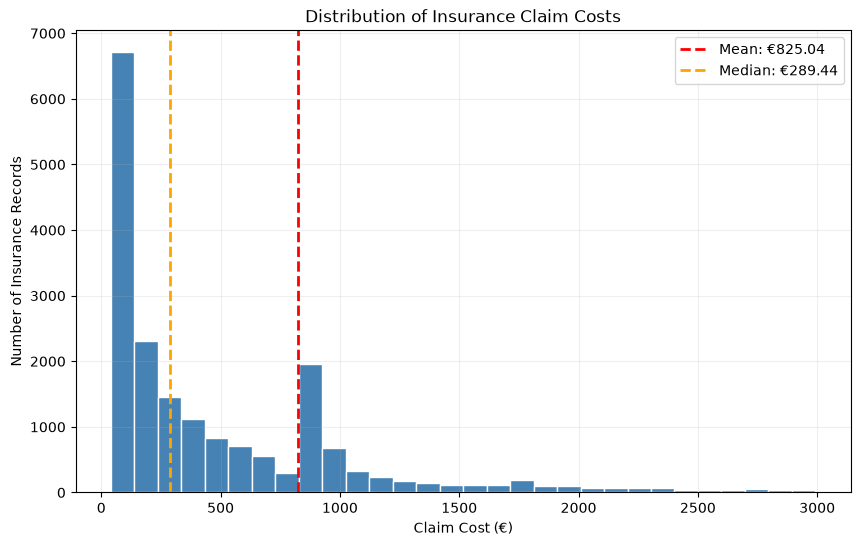

In [145]:
# Focus on claim costs up to €3,000
visible_costs = claim_costs[claim_costs <= 3000]

# Create the histogram
plt.figure(figsize=(10, 6))

plt.hist(
    visible_costs,
    bins=30,
    color='steelblue',
    edgecolor='white'
)

# Add the mean and median
plt.axvline(
    mean_cost,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean: €{mean_cost:,.2f}'
)

plt.axvline(
    median_cost,
    color='orange',
    linestyle='--',
    linewidth=2,
    label=f'Median: €{median_cost:,.2f}'
)

# Chart labels
plt.title('Distribution of Insurance Claim Costs')
plt.xlabel('Claim Cost (€)')
plt.ylabel('Number of Insurance Records')

plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 4.2 How Are Vehicle Characteristics Related to Insurance Premiums?

In the Linear Algebra section, we used vehicle characteristics to predict insurance premiums using multiple linear regression.

Now we will use **correlation analysis** to investigate how strongly each characteristic is related to the insurance premium.

We will examine three variables:
- **Power** — engine power.
- **Value_vehicle** — vehicle value.
- **Weight** — vehicle weight.

#### Pearson Correlation Coefficient

According to the Statistics lecture, the Pearson correlation coefficient measures the strength and direction of a linear relationship between two variables.

The formula is:

$$
r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}
\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$$

where:
- $r$ — the Pearson correlation coefficient.
- $x_i$ — a vehicle characteristic for record $i$.
- $y_i$ — the insurance premium for record $i$.
- $\bar{x}$ — the mean of the vehicle characteristic.
- $\bar{y}$ — the mean insurance premium.
- $n$ — the number of observations.

#### How We Will Use the Formula

We will calculate the correlation coefficient between each vehicle characteristic and the insurance premium.

The coefficient ranges from **-1 to +1**:

- **Close to +1:** strong positive linear relationship.
- **Close to -1:** strong negative linear relationship.
- **Close to 0:** weak or no linear relationship.

For example, a positive correlation between engine power and insurance premiums would indicate that more powerful vehicles tend to have higher premiums.

We will use Python to calculate the coefficients and create a bar chart to compare the results.

This will help us identify which vehicle characteristic has the strongest linear relationship with insurance premiums.

**Reference:**
- SoftUni, *Statistics

###  Calculating Pearson Correlation with Python

We will apply the Pearson correlation formula to measure the relationship between insurance premiums and three vehicle characteristics: engine power, vehicle value, and weight.

In [146]:
# Select the variables for correlation analysis
columns = ['Power', 'Value_vehicle', 'Weight', 'Premium']
correlation_data = df[columns].dropna()

# Calculate Pearson correlation using the mathematical formula
def pearson_correlation(x, y):
    x_mean = x.mean()
    y_mean = y.mean()

    numerator = np.sum((x - x_mean) * (y - y_mean))

    denominator = np.sqrt(
        np.sum((x - x_mean) ** 2) *
        np.sum((y - y_mean) ** 2)
    )

    return numerator / denominator

# Calculate correlations with insurance premiums
power_corr = pearson_correlation(
    correlation_data['Power'],
    correlation_data['Premium']
)

value_corr = pearson_correlation(
    correlation_data['Value_vehicle'],
    correlation_data['Premium']
)

weight_corr = pearson_correlation(
    correlation_data['Weight'],
    correlation_data['Premium']
)

# Display results
print(f"Power vs Premium: {power_corr:.4f}")
print(f"Vehicle Value vs Premium: {value_corr:.4f}")
print(f"Weight vs Premium: {weight_corr:.4f}")

Power vs Premium: 0.4317
Vehicle Value vs Premium: 0.4152
Weight vs Premium: 0.2988


### Visualizing Pearson Correlation

We will use a bar chart to compare the correlation coefficients between insurance premiums and three vehicle characteristics.

The chart will help us identify which characteristic has the strongest linear relationship with insurance premiums.

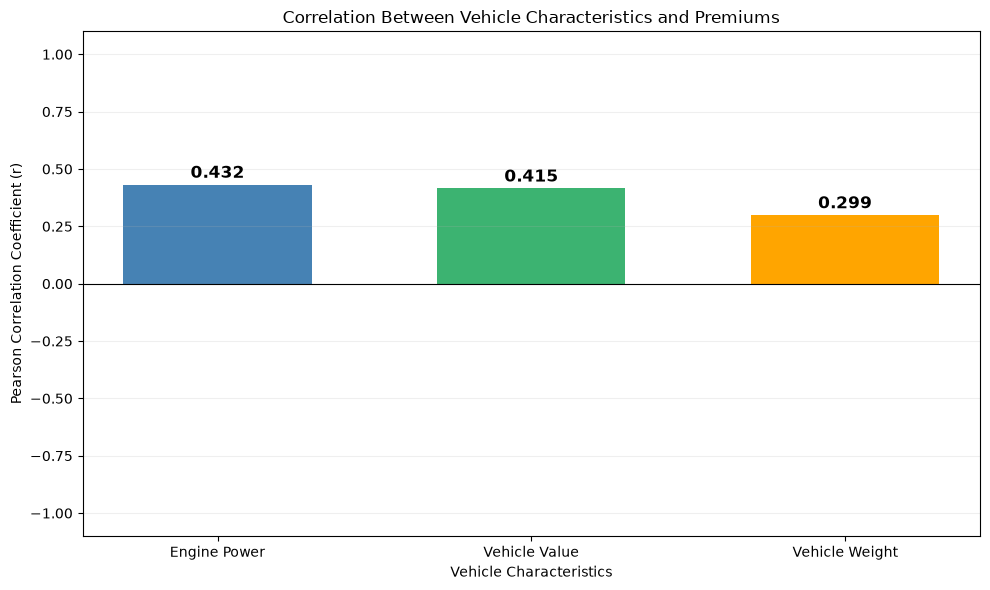

In [147]:
# Prepare correlation results
characteristics = ['Engine Power', 'Vehicle Value', 'Vehicle Weight']
correlations = [power_corr, value_corr, weight_corr]

# Create the bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    characteristics,
    correlations,
    color=['steelblue', 'mediumseagreen', 'orange'],
    width=0.6
)

# Display correlation values above or below the bars
for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + (0.03 if value >= 0 else -0.06),
        f'{value:.3f}',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

# Add a reference line at zero
plt.axhline(0, color='black', linewidth=0.8)

plt.title('Correlation Between Vehicle Characteristics and Premiums')
plt.xlabel('Vehicle Characteristics')
plt.ylabel('Pearson Correlation Coefficient (r)')

plt.ylim(-1.1, 1.1)
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()